# 02 · Modelling: Predicting Churn

**Goal:** estimate, for every customer, the **probability that they will churn**.
In notebook 03 we will use these probabilities to decide *who gets a retention offer*, so we need probabilities that are
**accurate and well-calibrated**, not just a yes/no label.

**Plan**
1. Split the data into training and test sets *before* anything else
2. Build a preprocessing pipeline
3. Compare a naive baseline with 3 models using cross-validation
4. Choose a model, then evaluate it once on the untouched test set
5. Explain what drives the predictions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             precision_recall_curve, confusion_matrix, classification_report, accuracy_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
RANDOM_STATE = 42

df = pd.read_csv("../data/telco_churn_clean.csv")
df.shape

(7043, 21)

## 1. Features, target and train/test split

- **Target (`y`):** `Churn` (1 = left).
- **Features (`X`):** everything except `customerID`, which is just a label and must never be a feature.

We hold back **20% as a test set** that we do not look at until the very end. It simulates new, unseen customers.
`stratify=y` keeps the 26.5% churn rate identical in both parts.

In [2]:
y = df["Churn"]
X = df.drop(columns=["Churn", "customerID"])

NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL = [c for c in X.columns if c not in NUMERIC]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} customers ({y_train.mean():.1%} churn)")
print(f"Test:  {len(X_test):,} customers ({y_test.mean():.1%} churn)")

Train: 5,634 customers (26.5% churn)
Test:  1,409 customers (26.5% churn)


## 2. Preprocessing pipeline

Models need numbers, so:
- **Categorical columns → one-hot encoding** (e.g. `Contract` becomes `Contract_One year`, `Contract_Two year`, …)
- **Numeric columns → standardised** (mean 0, std 1); this matters for logistic regression.

Everything goes inside a scikit-learn **`Pipeline`**. During cross-validation the scaler is then fitted *only* on the training
folds, never on the data it is evaluated on. That prevents **data leakage**, a common mistake that makes models look better than they are.

In [3]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), CATEGORICAL),
])

def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

n_features = preprocess.fit(X_train).transform(X_train).shape[1]
print(f"{X.shape[1]} original columns -> {n_features} model features after encoding")

19 original columns -> 40 model features after encoding


## 3. Which metrics?

Only 26.5% of customers churn, so **accuracy is misleading**. We use:

| Metric | Question it answers |
|---|---|
| **ROC-AUC** | If I pick one churner and one non-churner at random, how often does the model rank the churner as riskier? (0.5 = coin flip, 1.0 = perfect) |
| **PR-AUC** (average precision) | How well does the model find churners *without* many false alarms? Better suited to imbalanced data. Baseline = 0.265 |
| **Brier score** | How accurate are the probabilities themselves? (lower = better). Important for notebook 03 |

## 4. Compare models with 5-fold cross-validation

| Model | Why include it |
|---|---|
| **Dummy baseline** | Always predicts the average churn rate. Any real model must beat it |
| **Logistic regression** | Simple, fast, explainable, gives good probabilities |
| **Random forest** | Many decision trees voting; captures interactions automatically |
| **Gradient boosting** | Trees built one after another, each fixing earlier errors; often the strongest on tabular data |

Tree models are lightly regularised (minimum leaf size / shallow trees). With default settings the random forest overfits and scores lower (~0.82).

In [4]:
models = {
    "Dummy baseline": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results, fold_auc = [], {}
for name, model in models.items():
    r = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score", "accuracy": "accuracy"})
    fold_auc[name] = r["test_roc_auc"]
    cv_results.append({"Model": name,
                       "ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC std": r["test_roc_auc"].std(),
                       "PR-AUC": r["test_pr_auc"].mean(), "Brier": -r["test_brier"].mean(),
                       "Accuracy": r["test_accuracy"].mean()})
cv_results = pd.DataFrame(cv_results).set_index("Model")
cv_results

,ROC-AUC,ROC-AUC std,PR-AUC,Brier,Accuracy
Model,,,,,
Dummy baseline,0.500,0.000,0.265,0.195,0.735
Logistic regression,0.846,0.013,0.662,0.135,0.802
Random forest,0.845,0.010,0.658,0.136,0.803
Gradient boosting,0.848,0.011,0.668,0.134,0.805


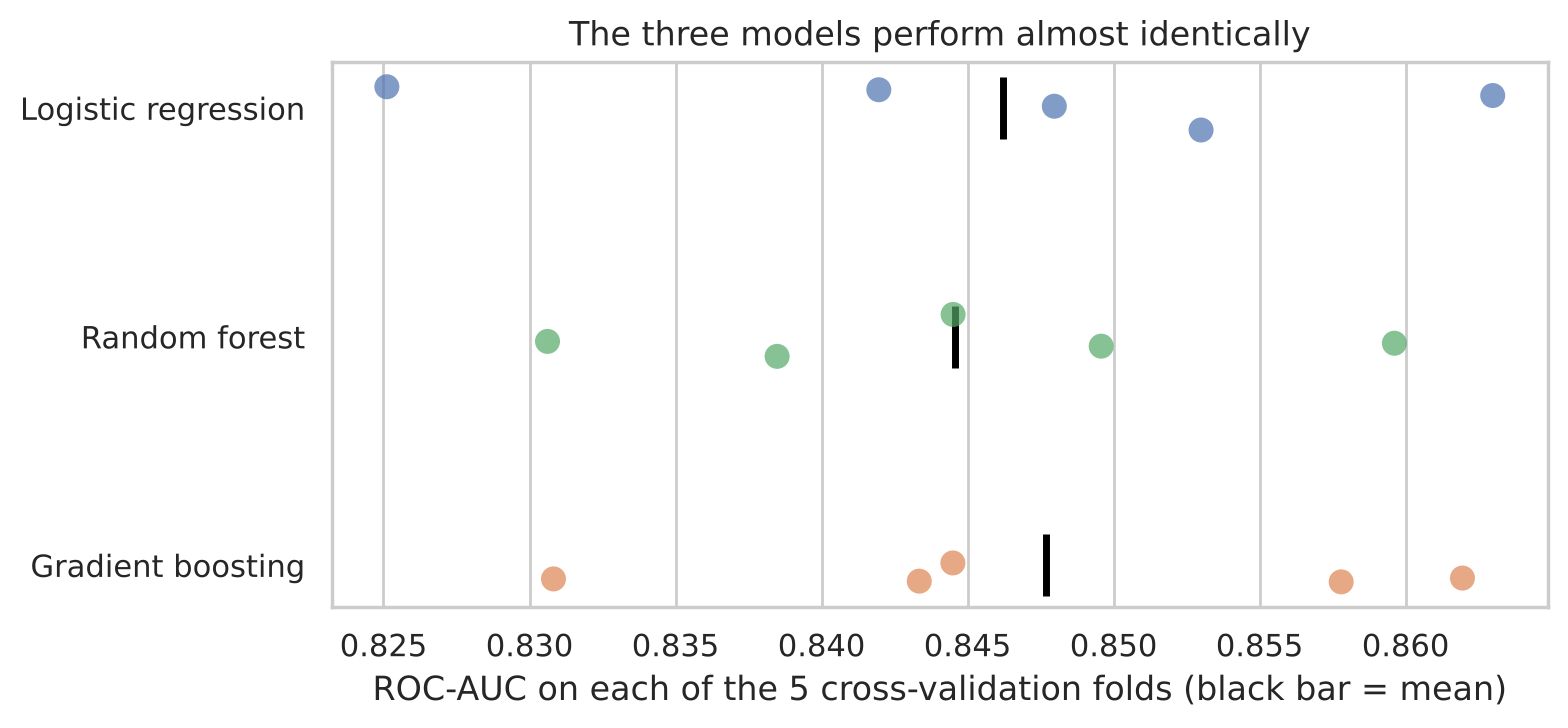

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
plot_df = pd.DataFrame({k: v for k, v in fold_auc.items() if k != "Dummy baseline"})
sns.stripplot(data=plot_df, orient="h", size=9, alpha=0.7, ax=ax, palette=["#4C72B0", "#55A868", "#DD8452"])
for i, col in enumerate(plot_df.columns):
    ax.plot(plot_df[col].mean(), i, marker="|", color="black", markersize=22, mew=2.5)
ax.set_xlabel("ROC-AUC on each of the 5 cross-validation folds (black bar = mean)")
ax.set_title("The three models perform almost identically")
plt.tight_layout()
plt.savefig("../reports/figures/02_cv_comparison.png", dpi=150)
plt.show()

### What this tells us

- Every real model clearly beats the baseline (ROC-AUC ~0.85 vs 0.50). Note the baseline's **73% "accuracy"**: proof that accuracy is useless here.
- The three models are **within ~0.003 ROC-AUC of each other**, while scores vary by ~0.01 between folds. The differences are **noise**, not real.

### Decision: logistic regression

When models perform equally, choose the **simplest** one:
1. **Explainable:** each feature has one coefficient a manager can understand ("a two-year contract cuts the odds of churn by X%").
2. **Good probabilities:** the Brier score is as good as the tree models, which matters for the profit calculation in notebook 03.
3. **Easy to deploy and maintain.**

We keep gradient boosting as a **benchmark** on the test set to confirm the decision.

## 5. Final evaluation on the untouched test set

In [6]:
final_model = make_pipeline(LogisticRegression(max_iter=2000)).fit(X_train, y_train)
benchmark = make_pipeline(models["Gradient boosting"]).fit(X_train, y_train)

p_test = final_model.predict_proba(X_test)[:, 1]
p_bench = benchmark.predict_proba(X_test)[:, 1]

test_scores = pd.DataFrame({
    "Logistic regression (chosen)": [roc_auc_score(y_test, p_test), average_precision_score(y_test, p_test), brier_score_loss(y_test, p_test)],
    "Gradient boosting (benchmark)": [roc_auc_score(y_test, p_bench), average_precision_score(y_test, p_bench), brier_score_loss(y_test, p_bench)],
}, index=["ROC-AUC", "PR-AUC", "Brier"]).T
test_scores

,ROC-AUC,PR-AUC,Brier
Logistic regression (chosen),0.842,0.634,0.138
Gradient boosting (benchmark),0.844,0.661,0.135


Test scores match the cross-validation scores, so the model **generalises** to new customers and isn't overfitted.

**Honest caveat:** gradient boosting has a higher PR-AUC on the test set (0.661 vs 0.634). The precision-recall curve below shows where:
it is more precise for the **very riskiest** customers (the first ~15% of churners). Across the rest of the curve the two are
nearly identical, and cross-validation PR-AUC was close (0.668 vs 0.662). We keep logistic regression for explainability, but if the business
only ever contacts a very small top slice of customers, gradient boosting would be worth revisiting.

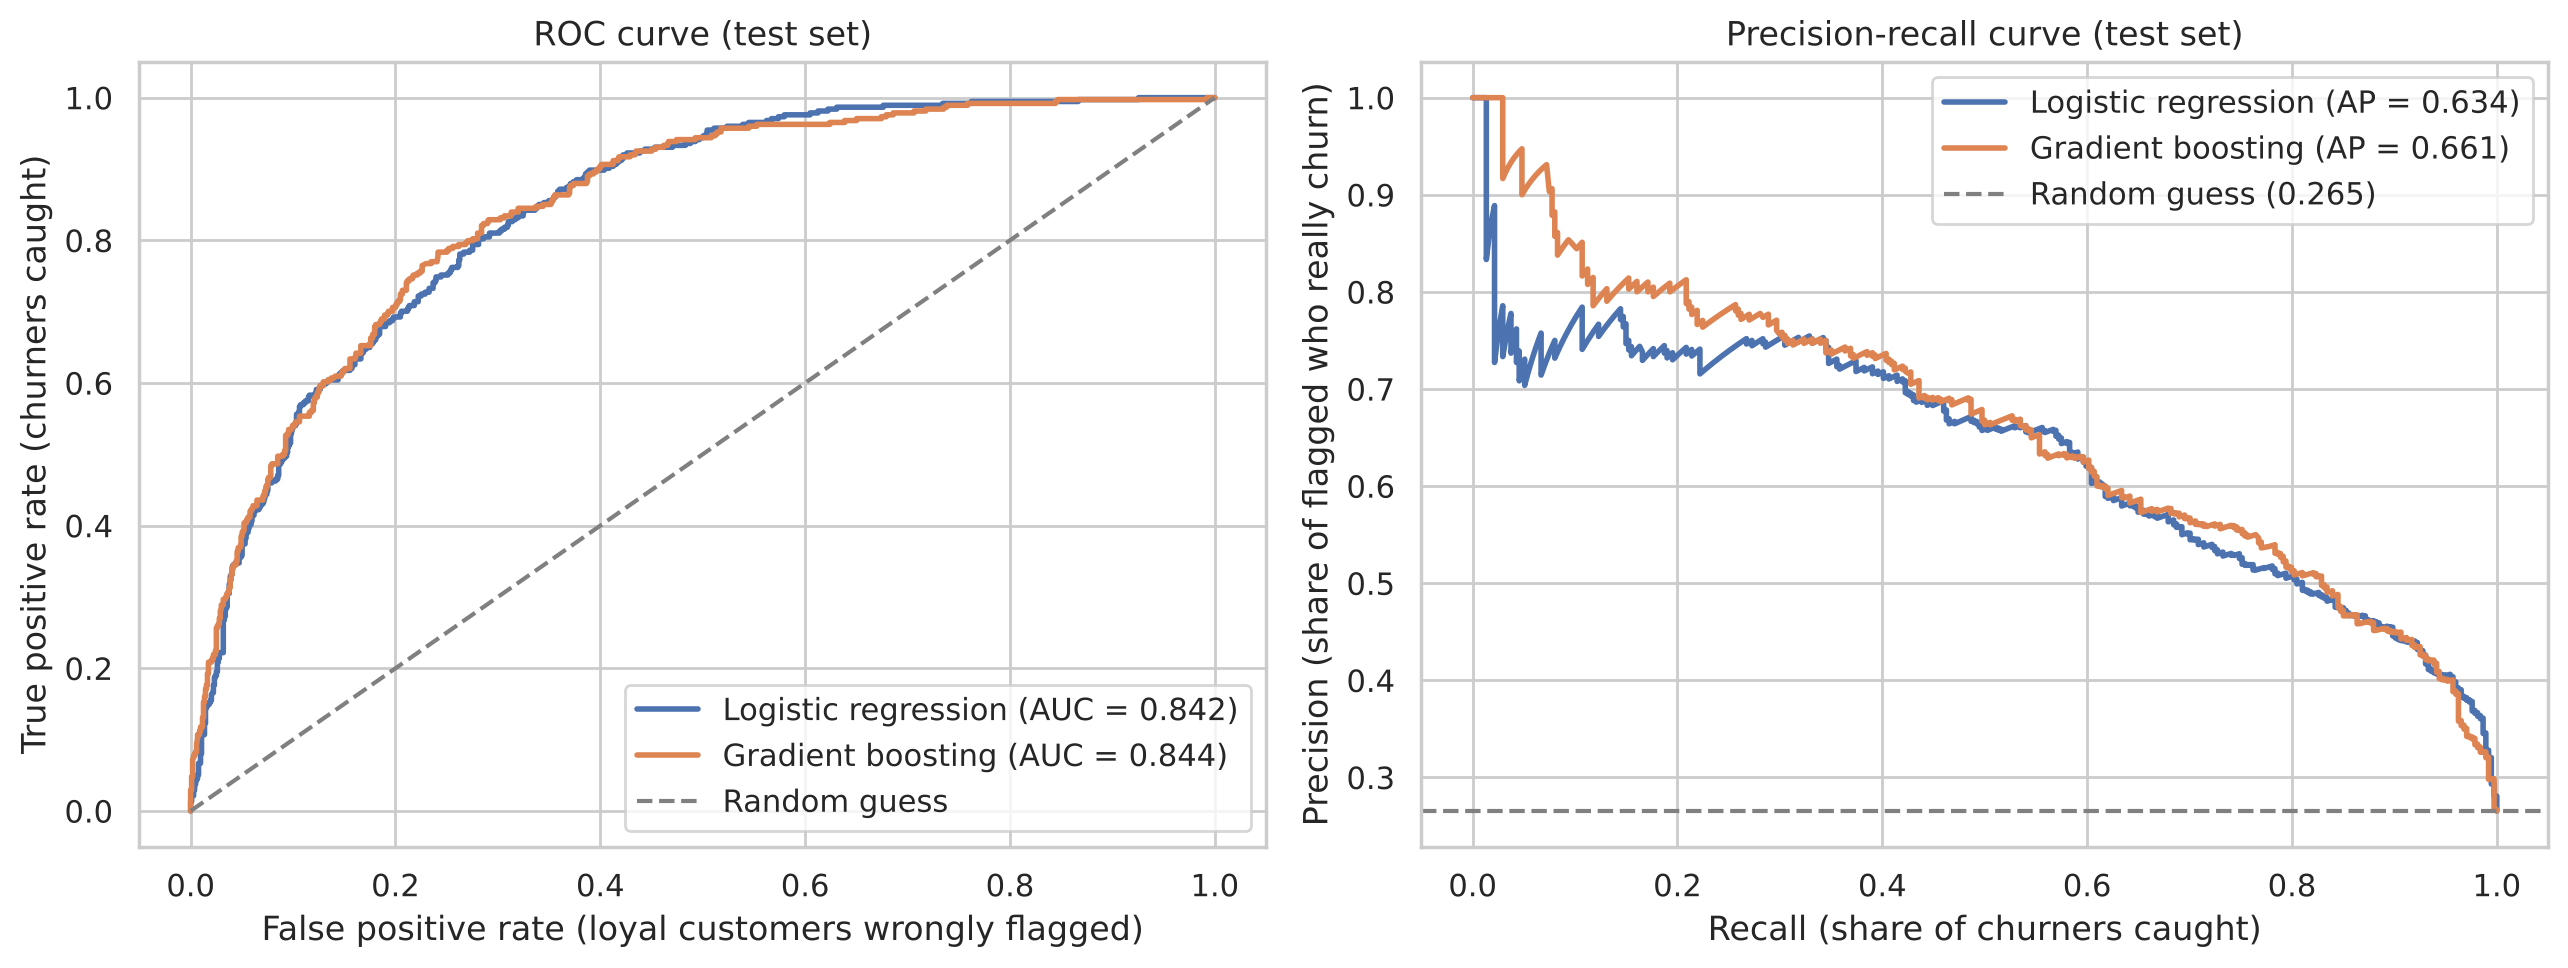

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for p, name, c in [(p_test, "Logistic regression", "#4C72B0"), (p_bench, "Gradient boosting", "#DD8452")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax1.plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax2.plot(rec, prec, color=c, lw=2, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
ax1.plot([0, 1], [0, 1], ls="--", color="grey", label="Random guess")
ax1.set_xlabel("False positive rate (loyal customers wrongly flagged)"); ax1.set_ylabel("True positive rate (churners caught)")
ax1.set_title("ROC curve (test set)"); ax1.legend(loc="lower right")
ax2.axhline(y_test.mean(), ls="--", color="grey", label=f"Random guess ({y_test.mean():.3f})")
ax2.set_xlabel("Recall (share of churners caught)"); ax2.set_ylabel("Precision (share of flagged who really churn)")
ax2.set_title("Precision-recall curve (test set)"); ax2.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../reports/figures/02_roc_pr.png", dpi=150)
plt.show()

### Predictions at the default 0.5 threshold

To turn probabilities into yes/no, the default rule is "flag if probability ≥ 0.5". Let's see what that gives:

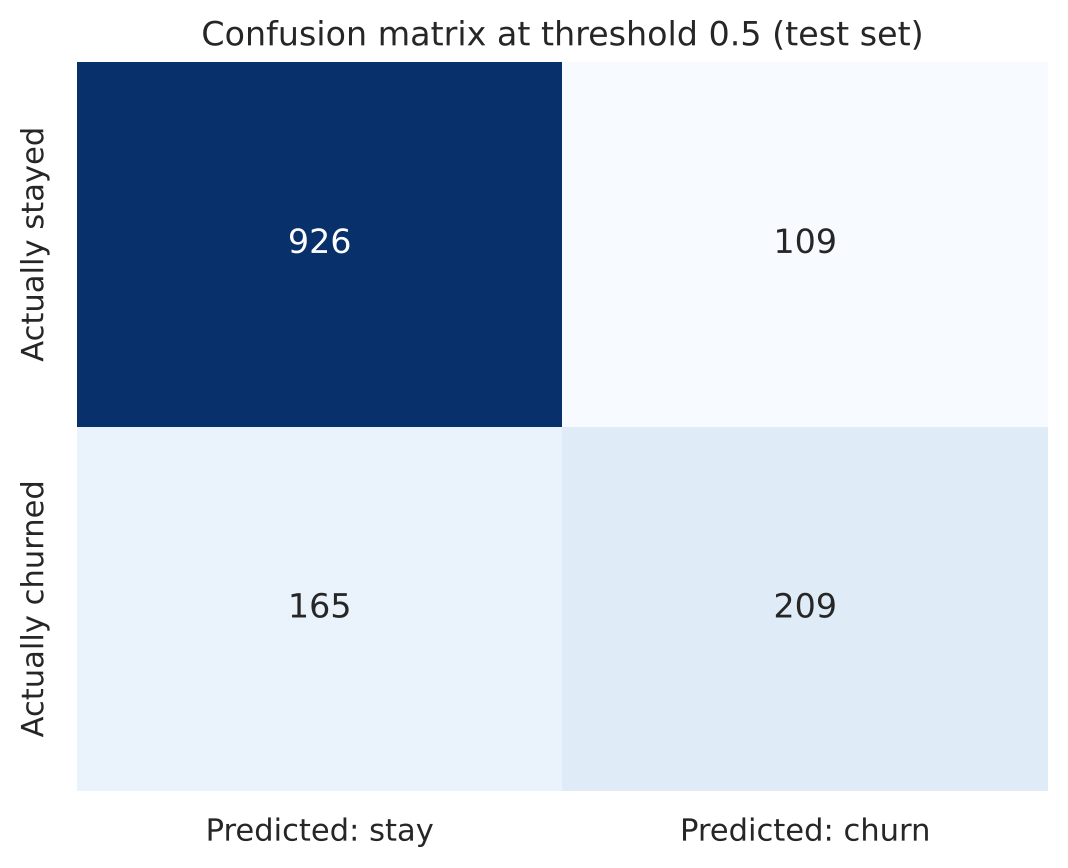

              precision    recall  f1-score   support

      Stayed      0.849     0.895     0.871      1035
     Churned      0.657     0.559     0.604       374

    accuracy                          0.806      1409
   macro avg      0.753     0.727     0.738      1409
weighted avg      0.798     0.806     0.800      1409



In [8]:
pred_05 = (p_test >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred_05)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted: stay", "Predicted: churn"], yticklabels=["Actually stayed", "Actually churned"])
ax.set_title("Confusion matrix at threshold 0.5 (test set)")
plt.tight_layout()
plt.savefig("../reports/figures/02_confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_test, pred_05, target_names=["Stayed", "Churned"], digits=3))

At 0.5 the model catches only **about half of the churners** (recall), and when it flags someone, it's right about 2 times out of 3 (precision).

**Is 0.5 the right threshold?** There's no reason it should be. Missing a churner (lost revenue) costs much more than
sending an unnecessary discount. The right threshold depends on **costs and benefits**, and finding it is the job of notebook 03.

## 6. Are the probabilities trustworthy? (calibration)

If the model says "30% risk" for a group of customers, about 30% of them should actually churn. Notebook 03 multiplies
probabilities by money, so this matters.

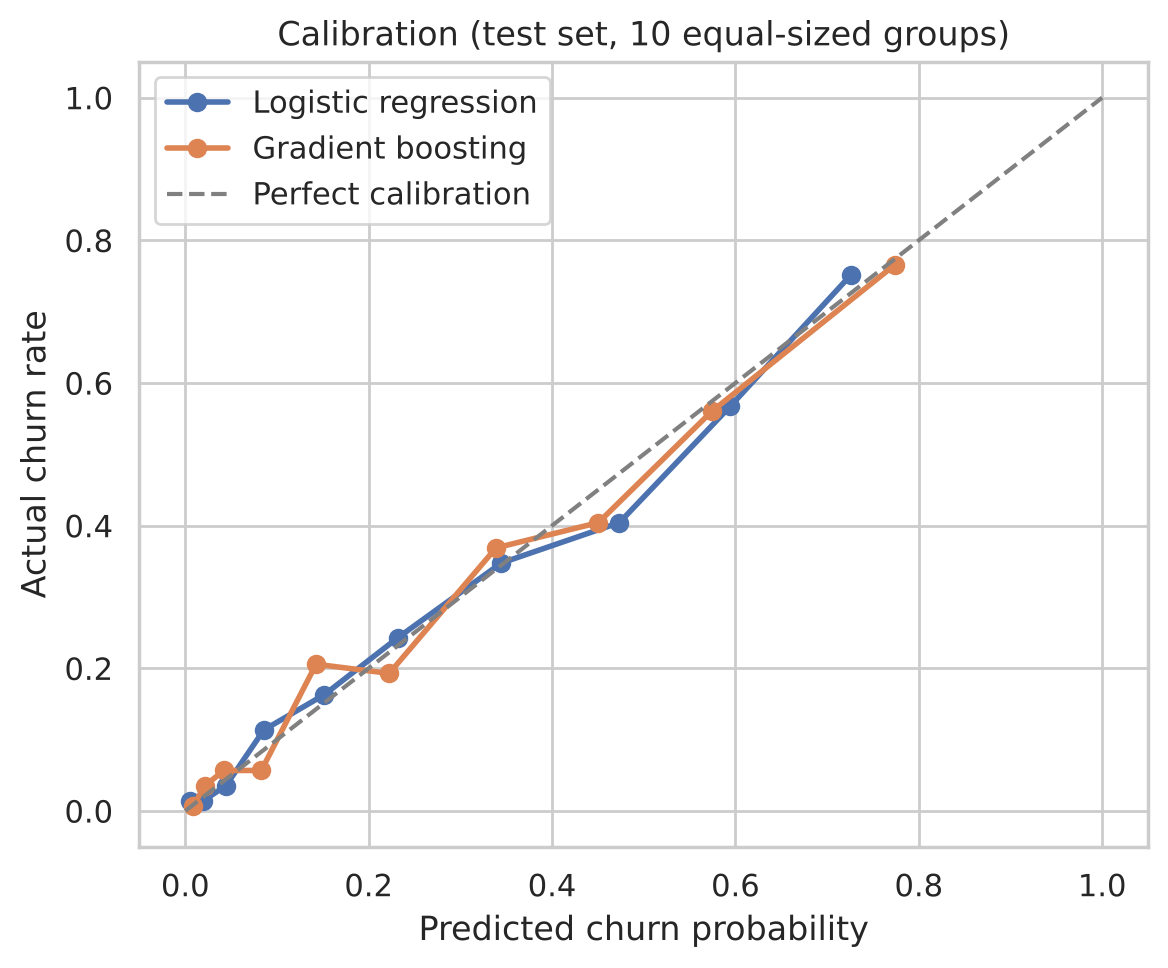

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for p, name, c in [(p_test, "Logistic regression", "#4C72B0"), (p_bench, "Gradient boosting", "#DD8452")]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", color=c, lw=2, label=name)
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="Perfect calibration")
ax.set_xlabel("Predicted churn probability"); ax.set_ylabel("Actual churn rate")
ax.set_title("Calibration (test set, 10 equal-sized groups)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/02_calibration.png", dpi=150)
plt.show()

Both curves sit close to the diagonal, so the predicted probabilities can be used directly as **expected churn rates**.

## 7. Business view: how well does the model rank customers? (gains)

A marketing team can only contact a limited number of customers. If they contact the **riskiest X%** first, what share of all churners do they reach?

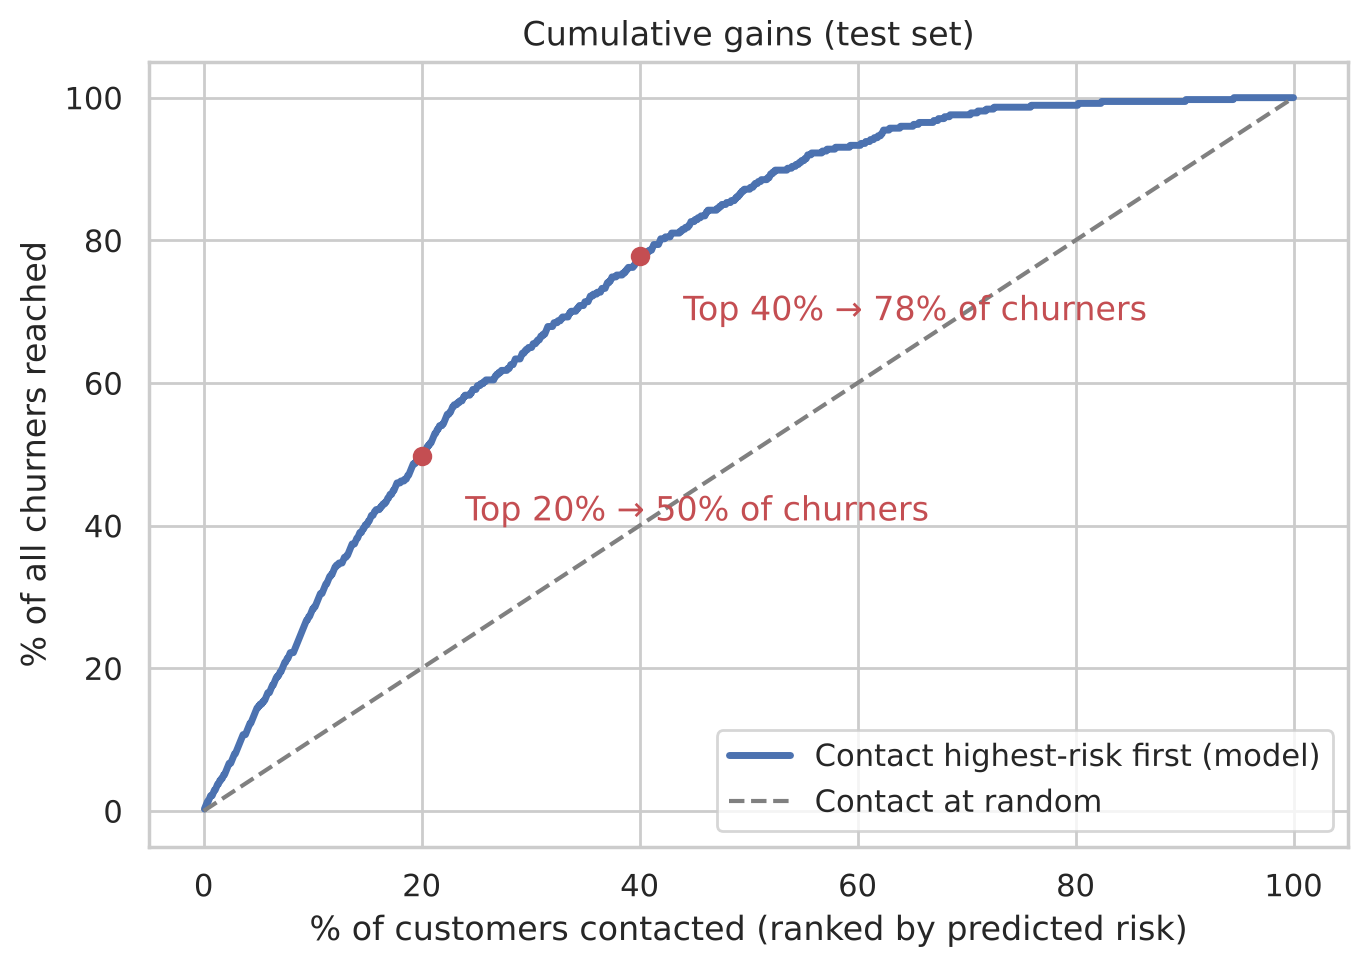

In [10]:
order = np.argsort(-p_test)
caught = np.cumsum(y_test.values[order]) / y_test.sum()
contacted = np.arange(1, len(order) + 1) / len(order)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(contacted * 100, caught * 100, color="#4C72B0", lw=2.5, label="Contact highest-risk first (model)")
ax.plot([0, 100], [0, 100], ls="--", color="grey", label="Contact at random")
for pct in [20, 40]:
    val = caught[int(len(order) * pct / 100) - 1] * 100
    ax.plot(pct, val, "o", color="#C44E52")
    ax.annotate(f"Top {pct}% → {val:.0f}% of churners", (pct, val), xytext=(pct + 4, val - 9), color="#C44E52")
ax.set_xlabel("% of customers contacted (ranked by predicted risk)"); ax.set_ylabel("% of all churners reached")
ax.set_title("Cumulative gains (test set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../reports/figures/02_gains.png", dpi=150)
plt.show()

## 8. What drives churn? Explaining the model

### Logistic regression coefficients as odds ratios

An **odds ratio** of 2.0 means that feature *doubles* the odds of churning (holding everything else equal); 0.5 means it *halves* them.
For numeric features the effect is per 1 standard deviation (e.g. ~25 months of tenure).

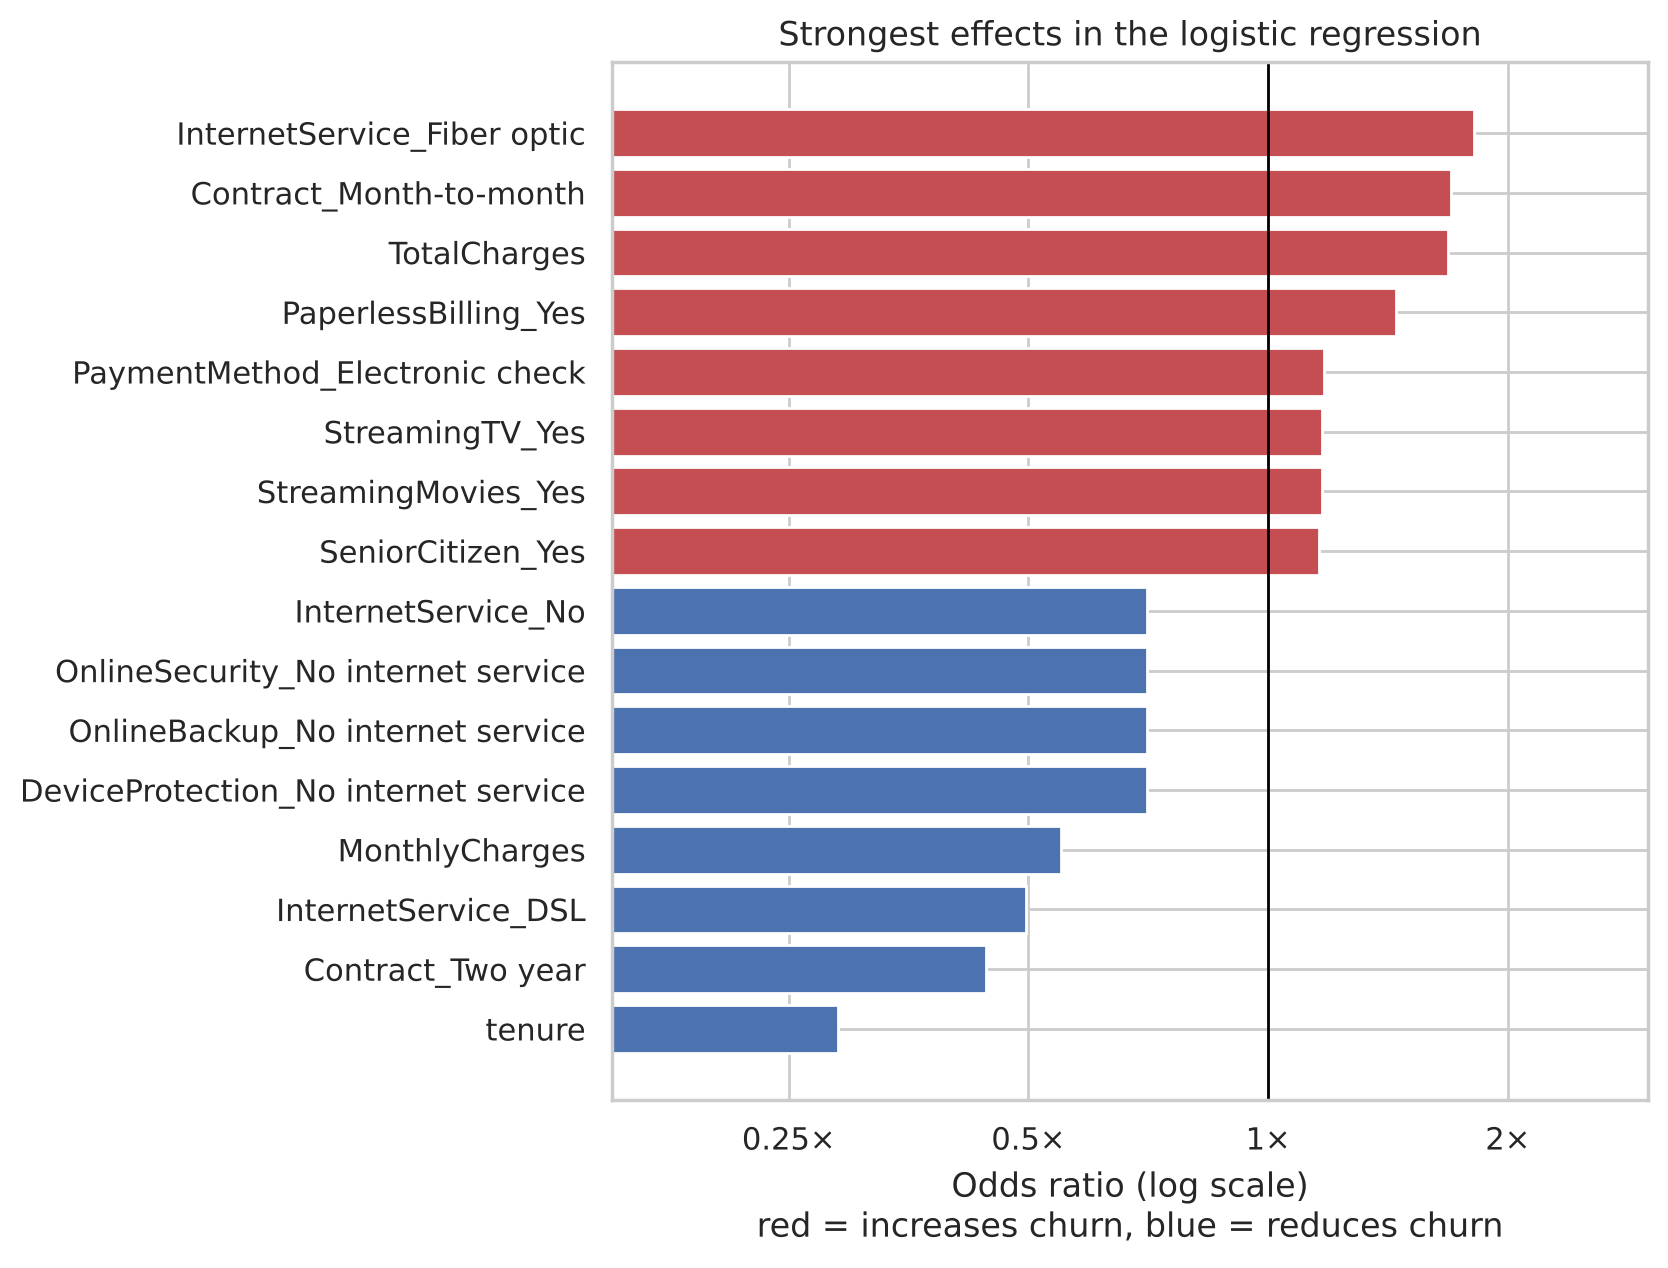

In [11]:
feature_names = final_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final_model.named_steps["model"].coef_[0], index=feature_names)
odds = np.exp(coefs).rename("Odds ratio")
odds.index = odds.index.str.replace("num__", "").str.replace("cat__", "")

top = pd.concat([odds.nlargest(8), odds.nsmallest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
colors = ["#C44E52" if v > 1 else "#4C72B0" for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set_xlim(0.15, 3)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([0.25, 0.5, 1, 2]); ax.set_xticklabels(["0.25×", "0.5×", "1×", "2×"])
ax.set_xlabel("Odds ratio (log scale)\nred = increases churn, blue = reduces churn")
ax.set_title("Strongest effects in the logistic regression")
plt.tight_layout()
plt.savefig("../reports/figures/02_odds_ratios.png", dpi=150)
plt.show()

> ⚠️ **Read coefficients with care.** `tenure`, `MonthlyCharges` and `TotalCharges` are strongly related
> (TotalCharges ≈ tenure × MonthlyCharges), so their individual coefficients can look odd: one may "absorb" another's effect.
> You can see it in the chart: **TotalCharges appears to *increase* churn and MonthlyCharges to *reduce* it**,
> the opposite of what the EDA showed. The model is splitting one shared effect between correlated columns. This is called **multicollinearity**:
> it doesn't hurt the predictions, but it makes single coefficients unreliable to interpret.
> That's why we also check **permutation importance**, which measures how much the model gets worse when a column is randomly shuffled.

### Permutation importance (on the test set)

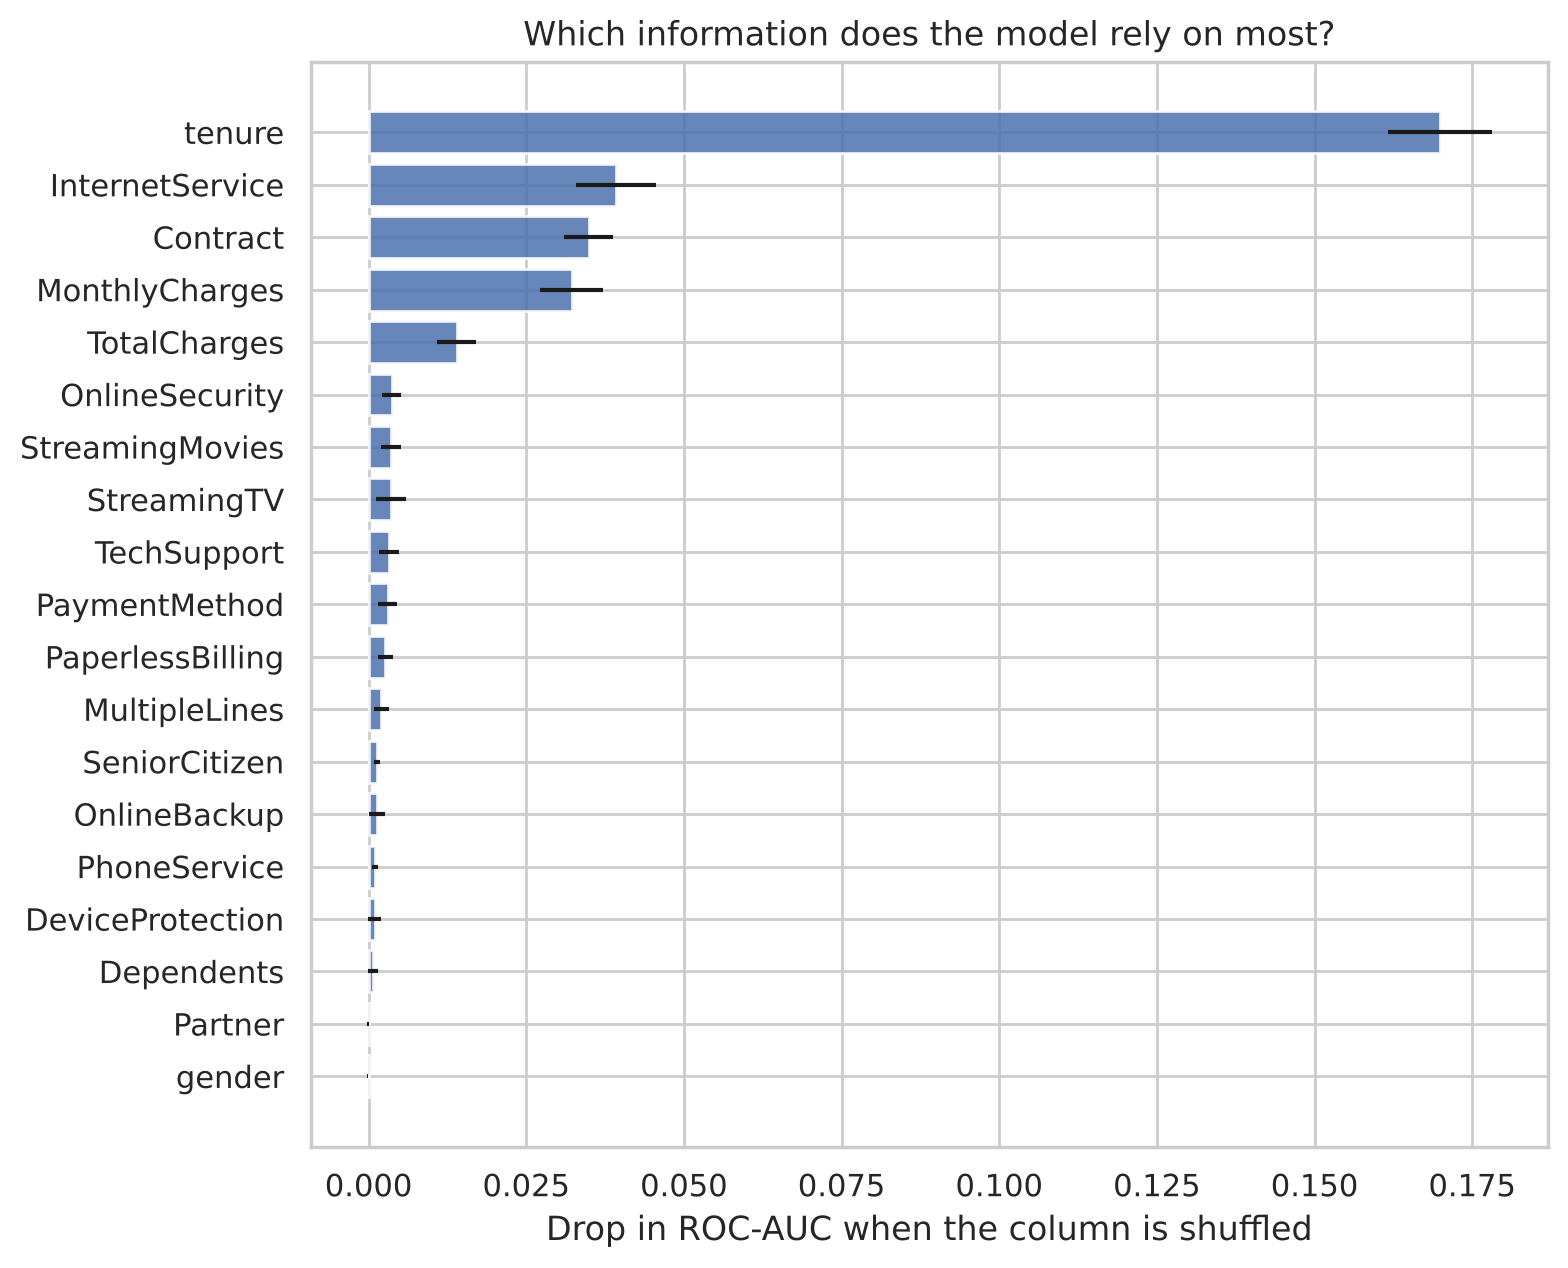

,importance,std
tenure,0.170,0.008
InternetService,0.039,0.006
Contract,0.035,0.004
MonthlyCharges,0.032,0.005
TotalCharges,0.014,0.003
OnlineSecurity,0.004,0.002


In [12]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"importance": perm.importances_mean, "std": perm.importances_std}, index=X_test.columns).sort_values("importance")

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(imp.index, imp["importance"], xerr=imp["std"], color="#4C72B0", alpha=0.85)
ax.set_xlabel("Drop in ROC-AUC when the column is shuffled")
ax.set_title("Which information does the model rely on most?")
plt.tight_layout()
plt.savefig("../reports/figures/02_permutation_importance.png", dpi=150)
plt.show()
imp.sort_values("importance", ascending=False).head(6)

**Tenure, contract type, internet service and monthly charges** carry most of the predictive power, which matches the EDA in notebook 01.
Demographics such as gender contribute almost nothing.

## 9. Save predictions for the decision analysis

In [13]:
out = X_test[["tenure", "Contract", "InternetService", "MonthlyCharges"]].copy()
out["customerID"] = df.loc[X_test.index, "customerID"]
out["churn_probability"] = p_test
out["actual_churn"] = y_test
out.to_csv("../data/test_predictions.csv", index=False)
out.sort_values("churn_probability", ascending=False).head()

,tenure,Contract,InternetService,MonthlyCharges,customerID,churn_probability,actual_churn
3380,1,Month-to-month,Fiber optic,95.100,5178-LMXOP,0.855,1
6866,1,Month-to-month,Fiber optic,95.450,0295-PPHDO,0.832,1
2631,7,Month-to-month,Fiber optic,99.250,6861-XWTWQ,0.828,1
6365,7,Month-to-month,Fiber optic,101.950,8884-ADFVN,0.822,1
4585,1,Month-to-month,Fiber optic,85.050,1069-XAIEM,0.819,1


## Key takeaways

1. All three models reach **ROC-AUC ≈ 0.84–0.85**, far above the 0.5 baseline.
2. **Logistic regression was chosen** because the complex models were not meaningfully better, and it is explainable with well-calibrated probabilities.
3. **Accuracy is misleading** here: the do-nothing baseline scores 73%.
4. Contacting the **riskiest 20% of customers reaches about half of all churners**; random targeting reaches 20%.
5. At the default 0.5 threshold, about half of churners are missed. The threshold should be set by **business costs**, not convention.

**Next → `03_decision_analysis.ipynb`:** put money on every decision and find the threshold that **maximises profit**.